Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [1]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features_4_gpt-4.1-mini_freeform.csv"
MODEL_TAG    = "gpt-4.1-mini-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features_4_gpt-4.1-mini_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-4.1-mini-freeform


## 1. Load & Inspect

In [2]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 126)
Feature cols : ['molecular_weight', 'heavy_atom_count', 'atom_count', 'carbon_count', 'nitrogen_count', 'oxygen_count', 'hydrogen_count', 'aromatic_atom_count', 'aromatic_bond_count', 'rotatable_bond_count', 'hydrogen_bond_donor_count', 'hydrogen_bond_acceptor_count', 'topological_polar_surface_area', 'logp', 'formal_charge', 'ring_count', 'aromatic_ring_count', 'heteroatom_count', 'heterocycle_count', 'amide_bond_count', 'ketone_count', 'aldehyde_count', 'carboxylic_acid_count', 'ester_count', 'ether_count', 'halogen_count', 'sulfur_count', 'phosphorus_count', 'positive_charge_count', 'negative_charge_count', 'molar_refractivity', 'fraction_csp3', 'heavy_atom_molecular_weight', 'num_heteroatoms', 'num_heteroaromatic_rings', 'num_fused_rings', 'num_spiro_rings', 'num_bridgehead_atoms', 'num_tautomers_possible', 'num_amine_groups', 'num_imidazole_like_rings', 'num_pyrimidine_like_rings', 'num_keto_groups', 'num_amide_groups', 'num_nitro_groups', 'num_sulfonami

,molecular_weight,heavy_atom_count,atom_count,carbon_count,nitrogen_count,oxygen_count,hydrogen_count,aromatic_atom_count,aromatic_bond_count,rotatable_bond_count,...,num_fused_heteroaliphatic_rings,num_fused_aliphatic_rings,num_fused_aromatic_carbons,num_fused_aromatic_nitrogens,num_fused_aromatic_oxygens,num_fused_aromatic_sulfurs,num_fused_aromatic_phosphorus,input,prestwick_ID,smiles_resolution
0,152.12,9,12,2,5,1,4,7,6,0,...,0,0,2,5,1,0,0,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast
1,173.18,11,20,6,4,2,8,6,6,1,...,0,0,0,0,0,0,0,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast
2,261.29,18,29,12,3,3,11,12,13,3,...,0,0,6,1,0,1,0,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast


In [3]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                 dtype  nulls
molecular_weight               float64      0
heavy_atom_count                 int64      0
atom_count                       int64      0
carbon_count                     int64      0
nitrogen_count                   int64      0
...                                ...    ...
num_fused_aromatic_carbons       int64      0
num_fused_aromatic_nitrogens     int64      0
num_fused_aromatic_oxygens       int64      0
num_fused_aromatic_sulfurs       int64      0
num_fused_aromatic_phosphorus    int64      0

[123 rows x 2 columns]


,molecular_weight,heavy_atom_count,atom_count,carbon_count,nitrogen_count,oxygen_count,hydrogen_count,aromatic_atom_count,aromatic_bond_count,rotatable_bond_count,...,num_fused_aromatic_rings,num_fused_nonaromatic_rings,num_fused_heteroaromatic_rings,num_fused_heteroaliphatic_rings,num_fused_aliphatic_rings,num_fused_aromatic_carbons,num_fused_aromatic_nitrogens,num_fused_aromatic_oxygens,num_fused_aromatic_sulfurs,num_fused_aromatic_phosphorus
count,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,...,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.0
mean,270.450,18.561,37.690,14.050,2.285,3.264,18.234,7.688,7.681,4.388,...,0.450,0.485,0.328,0.187,0.364,2.354,0.418,0.083,0.049,0.0
std,119.736,8.402,17.972,6.388,2.086,3.369,10.133,4.830,5.017,2.652,...,0.705,1.038,0.587,0.487,0.942,3.665,0.915,0.441,0.239,0.0
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
25%,192.120,14.000,26.000,10.000,1.000,1.000,12.000,6.000,6.000,3.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
50%,247.330,18.000,34.000,14.000,2.000,3.000,16.000,7.000,7.000,4.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
75%,327.310,22.000,43.000,18.000,3.000,4.000,22.000,12.000,12.000,6.000,...,1.000,0.000,1.000,0.000,0.000,5.000,0.000,0.000,0.000,0.0
max,1151.340,153.000,280.000,70.000,22.000,38.000,150.000,30.000,32.000,38.000,...,4.000,5.000,3.000,4.000,5.000,18.000,6.000,6.000,4.000,0.0


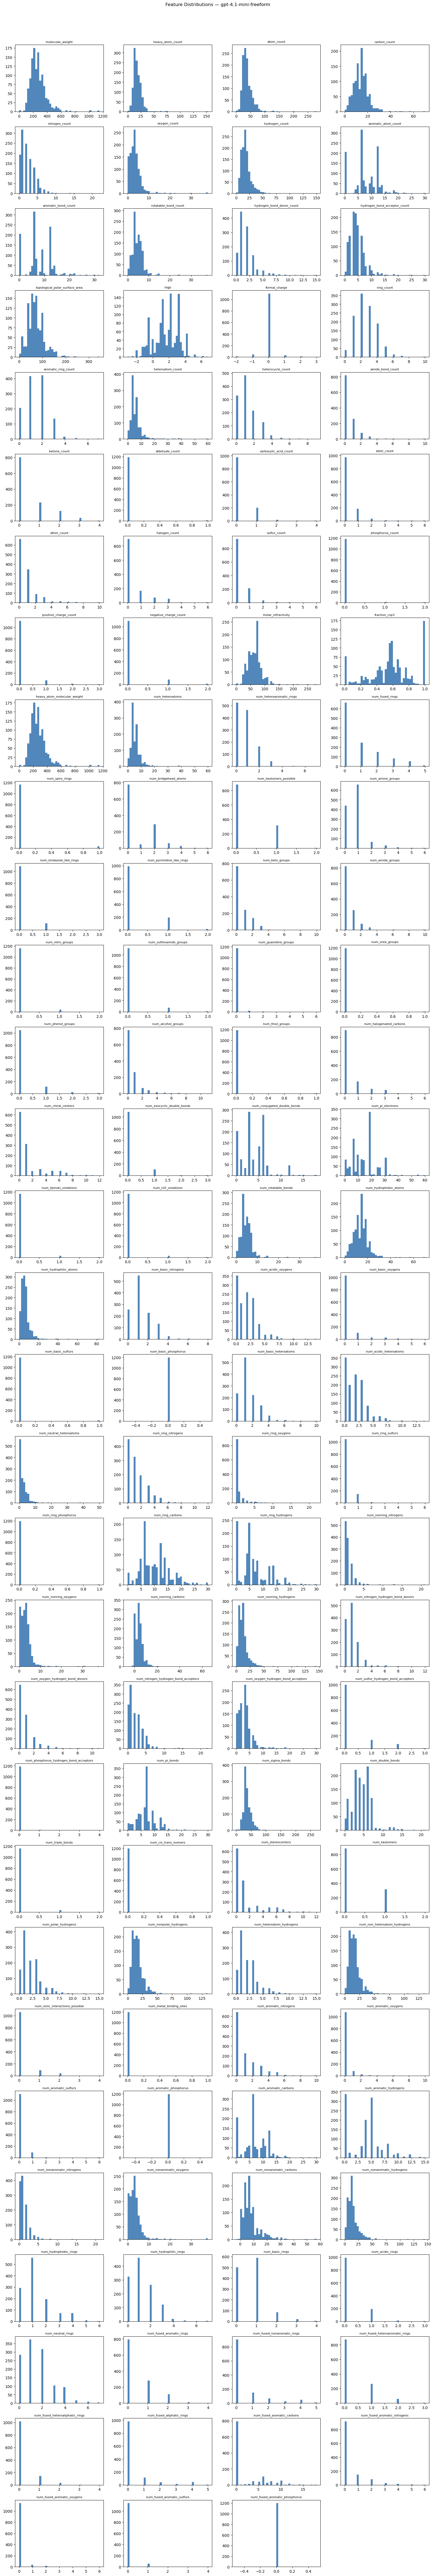

In [4]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [5]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 4
  molecular_weight                           -> MolWt
  topological_polar_surface_area             -> TPSA
  fraction_csp3                              -> FractionCSP3
  num_rotatable_bonds                        -> NumRotatableBonds


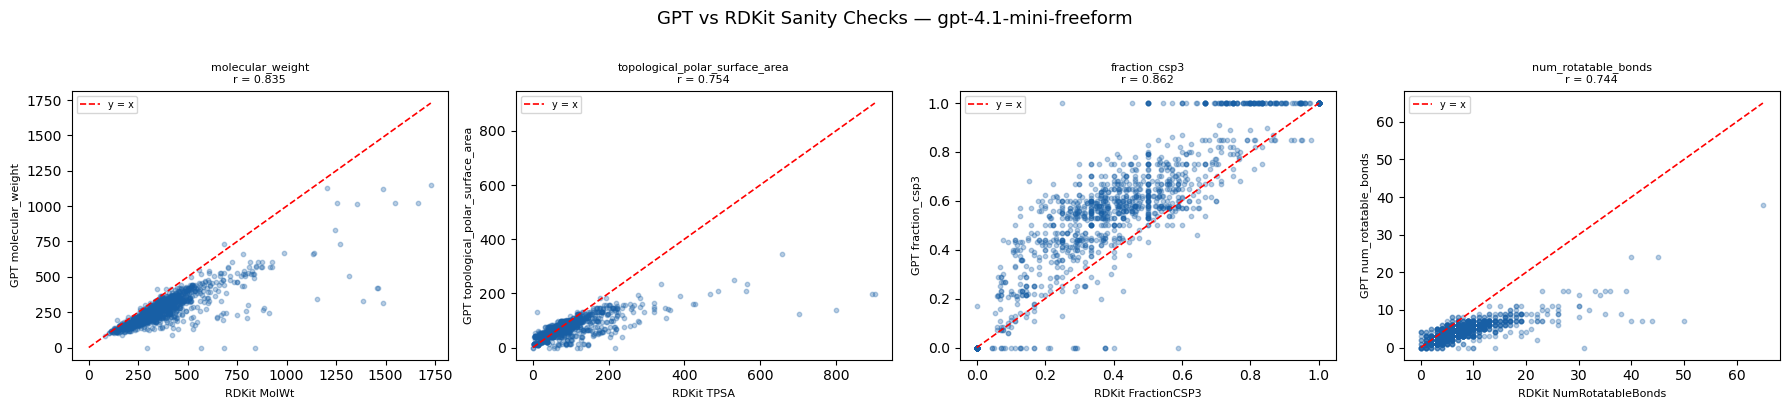

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1,152.117,152.120,0.00
1,Prestw-1207,180.159,180.157,-0.00
2,Prestw-1268,124.139,124.137,-0.00
3,Prestw-868,151.165,151.163,-0.00
4,Prestw-1069,153.137,153.130,-0.01



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-401,344.495,414.570,70.08
1,Prestw-1023,141.258,192.124,50.87
2,Prestw-405,685.904,729.900,44.00
3,Prestw-285,392.580,416.570,23.99
4,Prestw-204,261.252,280.220,18.97



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-160,1488.807,317.33,-1171.48
1,Prestw-506,1385.461,327.31,-1058.15
2,Prestw-159,1461.429,419.39,-1042.04
3,Prestw-321,1457.397,421.39,-1036.01
4,Prestw-455,841.068,0.00,-841.07


In [6]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

## 3. Cross-Correlation: RDKit vs Freeform GPT

RDKit: 96 features  |  GPT freeform: 120 features


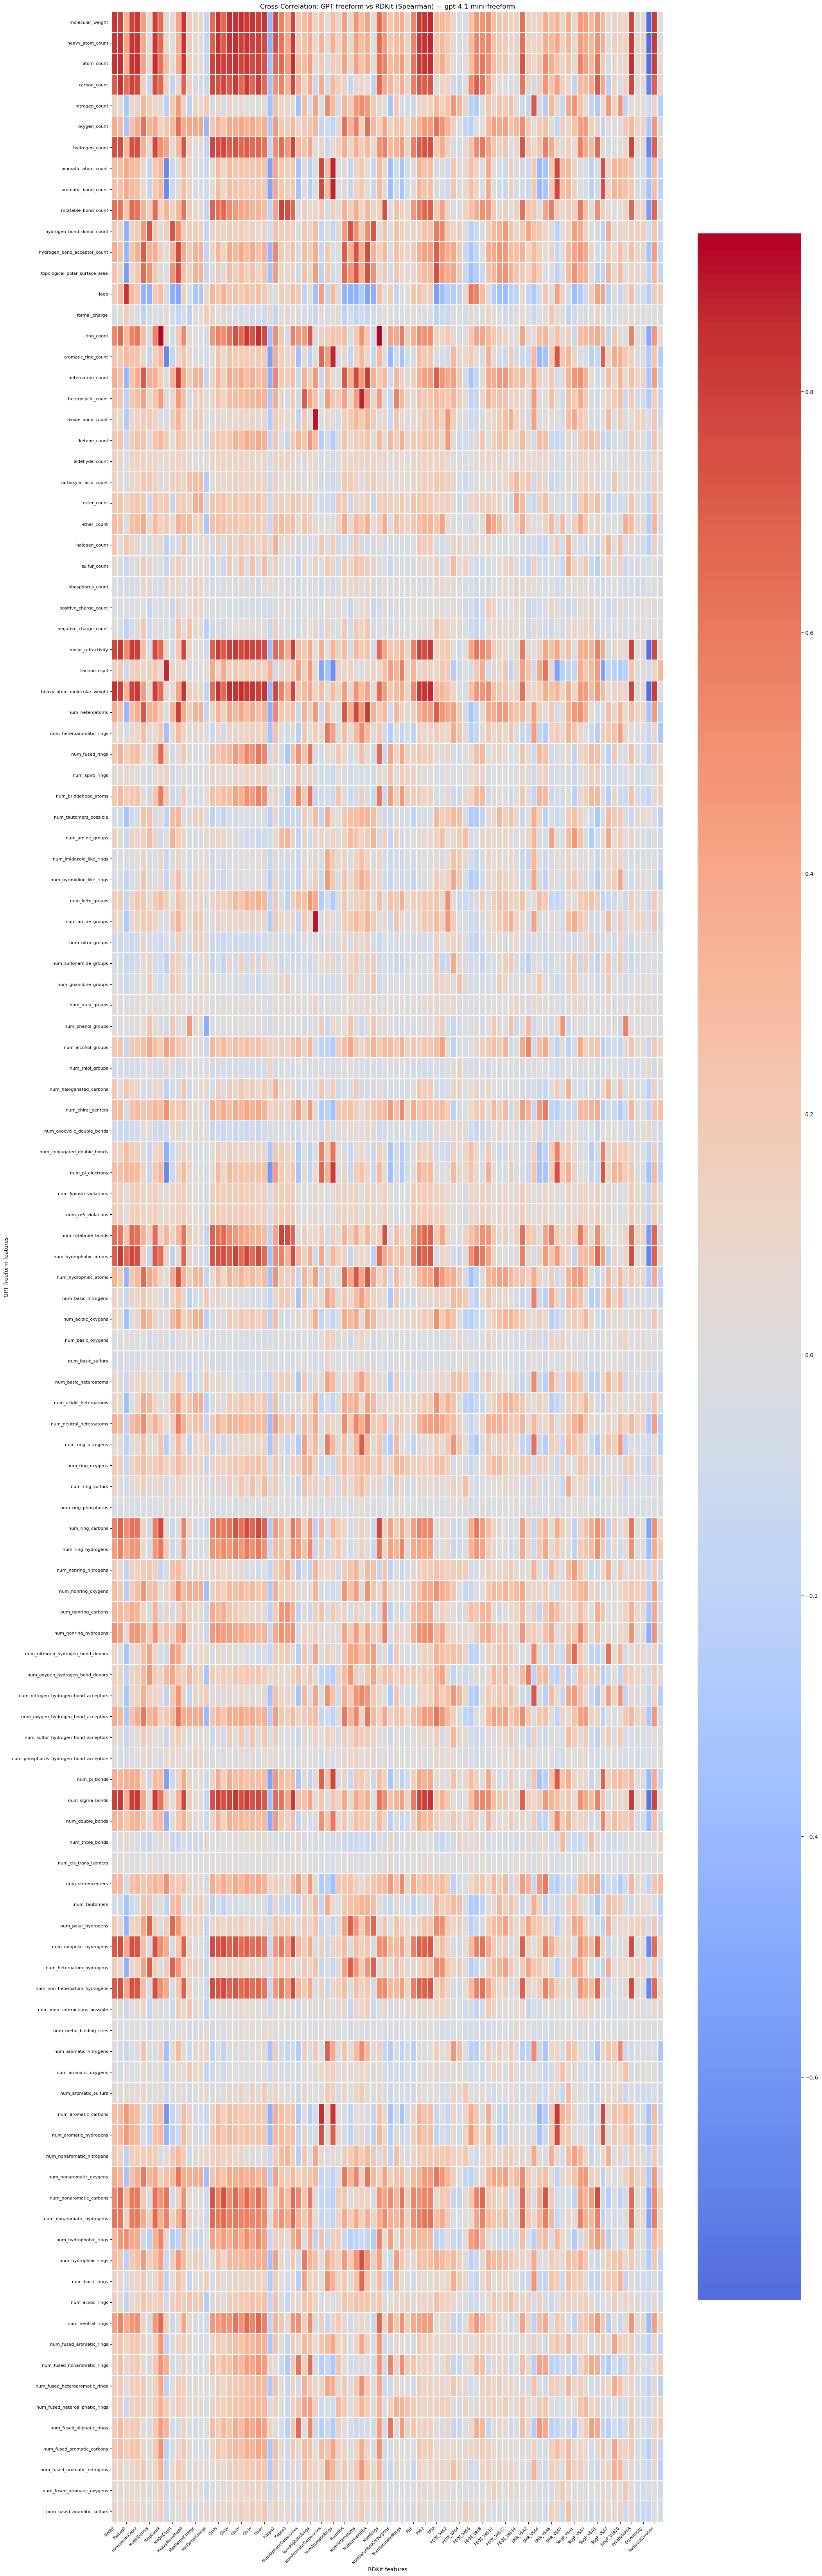

In [7]:
rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

# Compute only the GPT × RDKit cross-correlation block
combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr   # keep for novelty cell downstream

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]

# Clean axis labels (remove prefixes)
cross_block.index   = [c.replace("gpt__", "")   for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

fig, ax = plt.subplots(figsize=(max(20, n_rdkit * 0.22), max(4, n_gpt * 0.55)))
sns.heatmap(cross_block, cmap="coolwarm", center=0, annot=(n_gpt <= 30),
            fmt=".2f", linewidths=0.3, rasterized=True, ax=ax)
ax.set_title(f"Cross-Correlation: GPT freeform vs RDKit (Spearman) — {MODEL_TAG}", fontsize=12)
ax.set_xlabel("RDKit features", fontsize=10)
ax.set_ylabel("GPT freeform features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap, BoundaryNorm

N_CLUSTERS = 4
PALETTE    = ['#C62828', '#1565C0', '#2E7D32', '#E65100']   # red / blue / green / amber

# ── 1. Ward hierarchical clustering on |Spearman| distance ───────────────────
dist = 1.0 - np.abs(corr_self.values)
dist = (dist + dist.T) / 2              # enforce symmetry
np.fill_diagonal(dist, 0.0)
dist = np.clip(dist, 0.0, None)

Z          = linkage(squareform(dist), method='ward')
leaf_order = leaves_list(Z)             # dendrogram-optimal leaf ordering
cl_ids     = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')

feat_ord = [gpt_labels[i] for i in leaf_order]
corr_ord = corr_self.values[np.ix_(leaf_order, leaf_order)]
cl_ord   = cl_ids[leaf_order]
n_f      = len(feat_ord)

# Positions of cluster boundaries (midpoint between last/first feature of adjacent clusters)
bounds = (np.where(np.diff(cl_ord) != 0)[0] + 0.5).tolist()

# ── 2. Figure layout: left strip | heatmap | colorbar ────────────────────────
fig     = plt.figure(figsize=(22, 22))
gs      = fig.add_gridspec(2, 3,
            width_ratios=[0.025, 1.0, 0.022],
            height_ratios=[0.025, 1.0],
            hspace=0.008, wspace=0.008)

ax_heat = fig.add_subplot(gs[1, 1])
ax_top  = fig.add_subplot(gs[0, 1], sharex=ax_heat)   # top cluster strip
ax_left = fig.add_subplot(gs[1, 0], sharey=ax_heat)   # left cluster strip
ax_cbar = fig.add_subplot(gs[1, 2])

cmap_cl = ListedColormap(PALETTE)
norm_cl = BoundaryNorm(np.arange(0.5, N_CLUSTERS + 1.5), cmap_cl.N)

# ── 3. Main heatmap ───────────────────────────────────────────────────────────
im = ax_heat.imshow(corr_ord, cmap='coolwarm', vmin=-1, vmax=1,
                    aspect='auto', interpolation='nearest', rasterized=True)
ax_heat.set_yticks(range(n_f))
ax_heat.set_yticklabels(feat_ord, fontsize=5.2)
ax_heat.set_xticks(range(n_f))
ax_heat.set_xticklabels(feat_ord, fontsize=5.2, rotation=90)
ax_heat.tick_params(axis='y', left=False)
ax_heat.tick_params(axis='x', bottom=True)

# White separator lines at cluster boundaries
for b in bounds:
    ax_heat.axhline(b, color='white', lw=2.5, zorder=5)
    ax_heat.axvline(b, color='white', lw=2.5, zorder=5)

# Cluster label badge at diagonal centre of each block
for ci in range(1, N_CLUSTERS + 1):
    idxs = np.where(cl_ord == ci)[0]
    if len(idxs):
        mid = (idxs[0] + idxs[-1]) / 2
        ax_heat.text(mid, mid, f'C{ci}', ha='center', va='center',
                    fontsize=13, fontweight='bold', color='white', zorder=7,
                    bbox=dict(boxstyle='round,pad=0.25', fc=PALETTE[ci-1],
                              alpha=0.80, ec='none'))

ax_heat.set_title(
    f'GPT-4.1-mini Feature Self-Correlation (Spearman)\n'
    f'Ward hierarchical clustering — {N_CLUSTERS} feature groups',
    fontsize=12, pad=10)

# ── 4. Left cluster colour strip ─────────────────────────────────────────────
ax_left.imshow(cl_ord.reshape(-1, 1), cmap=cmap_cl, norm=norm_cl,
               aspect='auto', interpolation='nearest')
for b in bounds:
    ax_left.axhline(b, color='white', lw=2.5, zorder=5)
for ci in range(1, N_CLUSTERS + 1):
    idxs = np.where(cl_ord == ci)[0]
    if len(idxs):
        ax_left.text(0, (idxs[0] + idxs[-1]) / 2, f'C{ci}',
                    ha='center', va='center', fontsize=7.5,
                    fontweight='bold', color='white', zorder=6)
ax_left.set_xticks([]); ax_left.set_yticks([])
ax_left.spines[:].set_visible(False)

# ── 5. Top cluster colour strip ───────────────────────────────────────────────
ax_top.imshow(cl_ord.reshape(1, -1), cmap=cmap_cl, norm=norm_cl,
              aspect='auto', interpolation='nearest')
for b in bounds:
    ax_top.axvline(b, color='white', lw=2.5, zorder=5)
ax_top.set_xticks([]); ax_top.set_yticks([])
ax_top.spines[:].set_visible(False)

# ── 6. Colorbar ───────────────────────────────────────────────────────────────
cb = plt.colorbar(im, cax=ax_cbar)
cb.set_label('Spearman ρ', fontsize=9)
cb.set_ticks([-1.0, -0.5, 0, 0.5, 1.0])
cb.ax.tick_params(labelsize=8)

# ── 7. Cluster legend ─────────────────────────────────────────────────────────
handles = [mpatches.Patch(color=PALETTE[i], label=f'Cluster {i+1}')
           for i in range(N_CLUSTERS)]
fig.legend(handles=handles, ncol=N_CLUSTERS, fontsize=10,
           title='Feature clusters', title_fontsize=10,
           loc='lower center', bbox_to_anchor=(0.45, 0.001),
           framealpha=0.9, frameon=True)

plt.savefig(OUT_DIR / 'self_corr_clustered.png', dpi=200, bbox_inches='tight')
plt.show()

# ── 8. Print cluster composition ─────────────────────────────────────────────
print(f'\n=== {N_CLUSTERS}-Cluster Composition (Ward linkage on |Spearman| distance) ===')
for ci in range(1, N_CLUSTERS + 1):
    members = [feat_ord[i] for i in range(n_f) if cl_ord[i] == ci]
    print(f'\nCluster {ci}  ({len(members)} features)  color={PALETTE[ci-1]}')
    for m in members:
        print(f'  {m}')


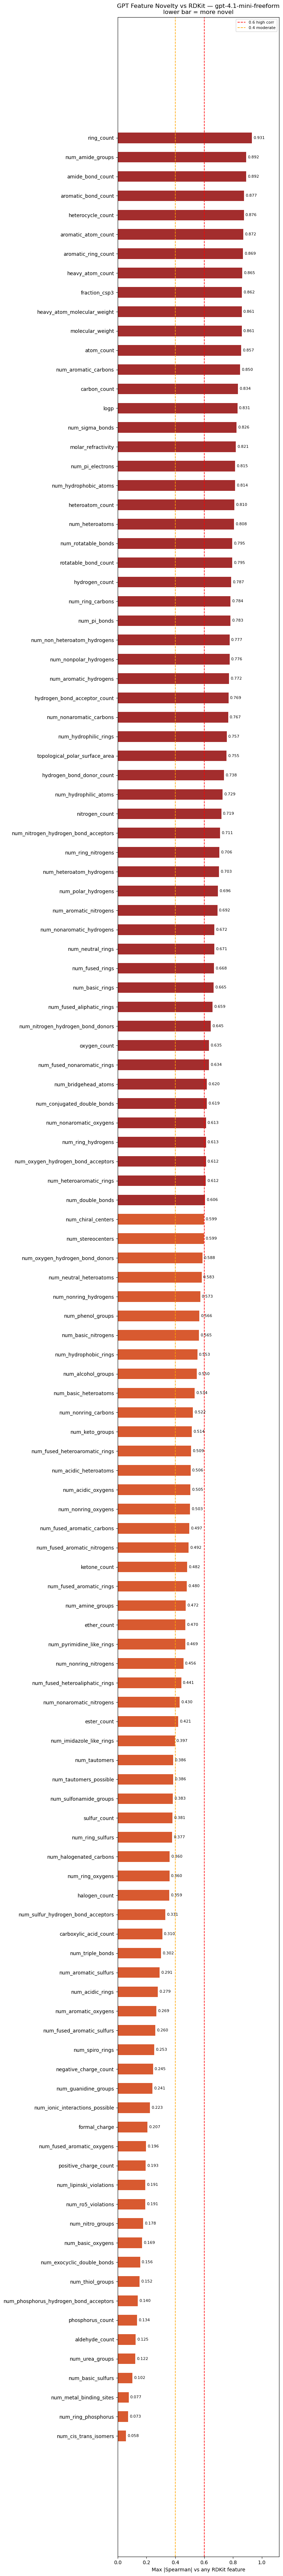

,gpt_feature,max_r_vs_rdkit,closest_rdkit
88,num_cis_trans_isomers,0.057684,NumSaturatedCarbocycles
71,num_ring_phosphorus,0.072934,FractionCSP3
96,num_metal_binding_sites,0.076545,PEOE_VAS14
64,num_basic_sulfurs,0.101640,NumAromaticHeterocycles
47,num_urea_groups,0.121602,NumAmideBonds
...,...,...,...
18,heterocycle_count,0.875815,NumHeterocycles
8,aromatic_bond_count,0.877424,NumAromaticRings
19,amide_bond_count,0.891742,NumAmideBonds
43,num_amide_groups,0.891742,NumAmideBonds


In [9]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

## 4. Build Feature Matrix

In [10]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

Dropped zero-variance: ['num_basic_phosphorus', 'num_aromatic_phosphorus', 'num_fused_aromatic_phosphorus']
Feature matrix: (1197, 121)  (123 -> 120 features)


In [11]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")

Pairs: (47880, 4)  |  label dist: {0: 41338, 1: 6542}
After merge: (47880, 124)  |  unmatched compounds: 0


## 5. XGBoost — Same Pipeline as `build_train.py`

In [14]:
def best_f1_threshold(y_true, scores):
    ps, rs, ths = precision_recall_curve(y_true, scores)
    f1s = 2 * ps[:-1] * rs[:-1] / np.clip(ps[:-1] + rs[:-1], 1e-12, None)
    return float(ths[int(np.nanargmax(f1s))]), float(f1s[int(np.nanargmax(f1s))])

def compute_metrics(y_true, scores, thr):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = (scores >= thr).astype(int)
    out = {}
    try:    out["roc_auc"] = float(roc_auc_score(y_true, scores))
    except: out["roc_auc"] = float("nan")
    try:    out["pr_auc"]  = float(average_precision_score(y_true, scores))
    except: out["pr_auc"]  = float("nan")
    out["threshold"] = float(thr)
    out["accuracy"]  = float(accuracy_score(y_true, y_pred))
    out["precision"] = float(precision_score(y_true, y_pred, zero_division=0))
    out["recall"]    = float(recall_score(y_true, y_pred, zero_division=0))
    out["f1"]        = float(f1_score(y_true, y_pred, zero_division=0))
    out["mcc"]       = float(matthews_corrcoef(y_true, y_pred)) \
                       if (y_pred.std() > 0 and y_true.std() > 0) else 0.0
    return out

def per_strain_metrics(df_split, y_true, scores, thr):
    df_ = df_split.reset_index(drop=True).copy()
    rows = []
    for bug, sub in df_.groupby("bacterium"):
        idx  = sub.index.values
        y, s = y_true[idx], scores[idx]
        try:    auc  = roc_auc_score(y, s)
        except: auc  = np.nan
        try:    aupr = average_precision_score(y, s)
        except: aupr = np.nan
        f1b = f1_score(y, (s >= thr).astype(int), zero_division=0)
        rows.append({"bacterium": bug, "n": len(y), "pos_rate": float(y.mean()),
                     "roc_auc": auc, "pr_auc": aupr, "f1_at_global_thr": f1b})
    out = pd.DataFrame(rows).sort_values("bacterium")
    return out, float(out["pr_auc"].mean(skipna=True))

PARAM_SPACE = {
    "eta":              [0.1, 0.05, 0.03],
    "max_depth":        [5, 8, 10],
    "subsample":        [0.5, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.8, 1.0],
    "min_child_weight": [1, 5],
    "gamma":            [0.0, 0.1],
}
BASE_PARAMS = {
    "tree_method": "hist", "max_bin": 512,
    "lambda": 1.0, "alpha": 0.0,
    "objective": "binary:logistic",
    "eval_metric": "aucpr", "verbosity": 0,
}

def sample_params():
    p = BASE_PARAMS.copy()
    for k, v in PARAM_SPACE.items():
        p[k] = random.choice(v)
    return p

print("Helpers loaded.")

Helpers loaded.


In [16]:
def train_xgb(joined, params, random_state=42):
    joined   = joined.copy()
    NON_FEAT = {"prestwick_ID", "bacterium", "label", "split"}
    cat_col  = ["bacterium"]
    gpt_cols = [c for c in joined.columns
                if c not in NON_FEAT
                and pd.api.types.is_numeric_dtype(joined[c])
                and (joined[joined["split"] == "train"][c] != 0).mean() >= 0.01]

    FEATURE_COLS = cat_col + gpt_cols
    print(f"  Features: {len(gpt_cols)} numeric + 1 cat ({len(FEATURE_COLS)} total)")

    df_tr  = joined[joined["split"] == "train"].copy()
    df_val = joined[joined["split"] == "val"].copy()
    df_te  = joined[joined["split"] == "test"].copy()

    y_tr  = df_tr["label"].astype(int).values
    y_val = df_val["label"].astype(int).values
    y_te  = df_te["label"].astype(int).values

    preproc = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_col),
        ("gpt", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0))]), gpt_cols),
    ])
    preproc.fit(df_tr[FEATURE_COLS], y_tr)

    X_tr  = preproc.transform(df_tr[FEATURE_COLS]).astype(np.float32)
    X_val = preproc.transform(df_val[FEATURE_COLS]).astype(np.float32)
    X_te  = preproc.transform(df_te[FEATURE_COLS]).astype(np.float32)

    pos_rate = y_tr.mean()
    p = params.copy()
    p["seed"]             = int(random_state)
    p["scale_pos_weight"] = (1 - pos_rate) / pos_rate
    p["max_delta_step"]   = 1

    dtr  = xgb.DMatrix(X_tr,  label=y_tr)
    dval = xgb.DMatrix(X_val, label=y_val)
    dte  = xgb.DMatrix(X_te,  label=y_te)

    booster = xgb.train(
        params=p, dtrain=dtr, num_boost_round=3000,
        evals=[(dval, "val")], early_stopping_rounds=300, verbose_eval=50
    )

    val_pred = booster.predict(dval)
    thr, _   = best_f1_threshold(y_val, val_pred)
    te_score = booster.predict(dte)
    overall  = compute_metrics(y_te, te_score, thr)

    per_strain_val_df, macro_pr_auc_val  = per_strain_metrics(df_val, y_val, val_pred, thr)
    per_strain_df,     macro_pr_auc_test = per_strain_metrics(df_te,  y_te,  te_score, thr)

    summary = {**overall,
               "val_macro_pr_auc_by_strain":  macro_pr_auc_val,
               "test_macro_pr_auc_by_strain": macro_pr_auc_test}

    preds = df_te.reset_index(drop=True)[["prestwick_ID", "bacterium", "label"]].copy()
    preds["proba"]   = te_score
    preds["pred_f1"] = (preds["proba"] >= thr).astype(int)

    feat_names = list(preproc.get_feature_names_out())
    return ({"preproc": preproc, "booster": booster, "threshold": thr,
             "feature_names": feat_names, "gpt_cols": gpt_cols},
            summary, preds, per_strain_df, dte, y_te)

print("train_xgb() defined.")

train_xgb() defined.


In [17]:
N_TRIALS = 5
SEEDS    = [0, 1, 2]
best_val, best_params = -1, None

for trial in range(N_TRIALS):
    print(f"\n[SEARCH] Trial {trial+1}/{N_TRIALS}")
    params     = sample_params()
    val_scores = []
    for seed in SEEDS:
        _, summary, _, _, _, _ = train_xgb(df, params=params, random_state=seed)
        val_scores.append(summary["val_macro_pr_auc_by_strain"])
    mean_val = float(np.mean(val_scores))
    print(f"  Mean val macro-AUPRC: {mean_val:.4f}")
    if mean_val > best_val:
        best_val, best_params = mean_val, params

print(f"\n[BEST] Val macro-AUPRC: {best_val:.4f}")
print(f"[BEST] Params: {best_params}")


[SEARCH] Trial 1/5
  Features: 114 numeric + 1 cat (115 total)
[0]	val-aucpr:0.31615
[50]	val-aucpr:0.56411
[100]	val-aucpr:0.60253
[150]	val-aucpr:0.62543
[200]	val-aucpr:0.62923
[250]	val-aucpr:0.62603
[300]	val-aucpr:0.62638
[350]	val-aucpr:0.62108
[400]	val-aucpr:0.61415
[450]	val-aucpr:0.61070
[492]	val-aucpr:0.60700
  Features: 114 numeric + 1 cat (115 total)
[0]	val-aucpr:0.31671
[50]	val-aucpr:0.55421
[100]	val-aucpr:0.58733
[150]	val-aucpr:0.60067
[200]	val-aucpr:0.60439
[250]	val-aucpr:0.60964
[300]	val-aucpr:0.60763
[350]	val-aucpr:0.60494
[400]	val-aucpr:0.60338
[450]	val-aucpr:0.60282
[500]	val-aucpr:0.59691
[550]	val-aucpr:0.58964
[578]	val-aucpr:0.58827
  Features: 114 numeric + 1 cat (115 total)
[0]	val-aucpr:0.23323
[50]	val-aucpr:0.56516
[100]	val-aucpr:0.60752
[150]	val-aucpr:0.62661
[200]	val-aucpr:0.62701
[250]	val-aucpr:0.62421
[300]	val-aucpr:0.62314
[350]	val-aucpr:0.62139
[400]	val-aucpr:0.62225
[450]	val-aucpr:0.62027
[476]	val-aucpr:0.61766
  Mean val macro-

In [18]:
model, summary, preds, per_strain_df, dte, y_te = train_xgb(
    df, params=best_params, random_state=0
)

print("\n================ RESULTS ================")
print(f"Mean per-strain AUPRC : {summary['test_macro_pr_auc_by_strain']:.4f}")
print(f"Test AUROC            : {summary['roc_auc']:.4f}")
print(f"Test AUPRC            : {summary['pr_auc']:.4f}")
print(f"Test F1               : {summary['f1']:.4f}")
print(f"Test Precision        : {summary['precision']:.4f}")
print(f"Test Recall           : {summary['recall']:.4f}")
print(f"Test MCC              : {summary['mcc']:.4f}")
print("=========================================")

  Features: 114 numeric + 1 cat (115 total)
[0]	val-aucpr:0.31615
[50]	val-aucpr:0.56411
[100]	val-aucpr:0.60253
[150]	val-aucpr:0.62543
[200]	val-aucpr:0.62923
[250]	val-aucpr:0.62603
[300]	val-aucpr:0.62638
[350]	val-aucpr:0.62108
[400]	val-aucpr:0.61415
[450]	val-aucpr:0.61070
[492]	val-aucpr:0.60700

================ RESULTS ================
Mean per-strain AUPRC : 0.6676
Test AUROC            : 0.8381
Test AUPRC            : 0.6606
Test F1               : 0.5916
Test Precision        : 0.5580
Test Recall           : 0.6296
Test MCC              : 0.5101


In [19]:
print("Per-strain metrics (test set):")
per_strain_df.sort_values("pr_auc", ascending=False)

Per-strain metrics (test set):


,bacterium,n,pos_rate,roc_auc,pr_auc,f1_at_global_thr
0,Akkermansia muciniphila (NT5021),120,0.100000,0.925154,0.794050,0.620690
32,Roseburia hominis (NT5079),120,0.166667,0.892500,0.785647,0.681818
27,Lactobacillus paracasei (NT5042),120,0.108333,0.877786,0.783770,0.606061
24,Eubacterium eligens (NT5075),120,0.200000,0.856337,0.778291,0.680000
31,Prevotella copri (NT5019),120,0.183333,0.882653,0.770682,0.695652
17,Clostridium saccharolyticum (NT5037),120,0.141667,0.852656,0.768671,0.684211
33,Roseburia intestinalis (NT5011),120,0.275000,0.858934,0.754639,0.676923
35,Ruminococcus gnavus (NT5046),120,0.216667,0.867021,0.750953,0.640000
36,Ruminococcus torques (NT5047),120,0.175000,0.844156,0.733543,0.571429
20,Dorea formicigenerans (NT5076),120,0.158333,0.815529,0.732914,0.634146


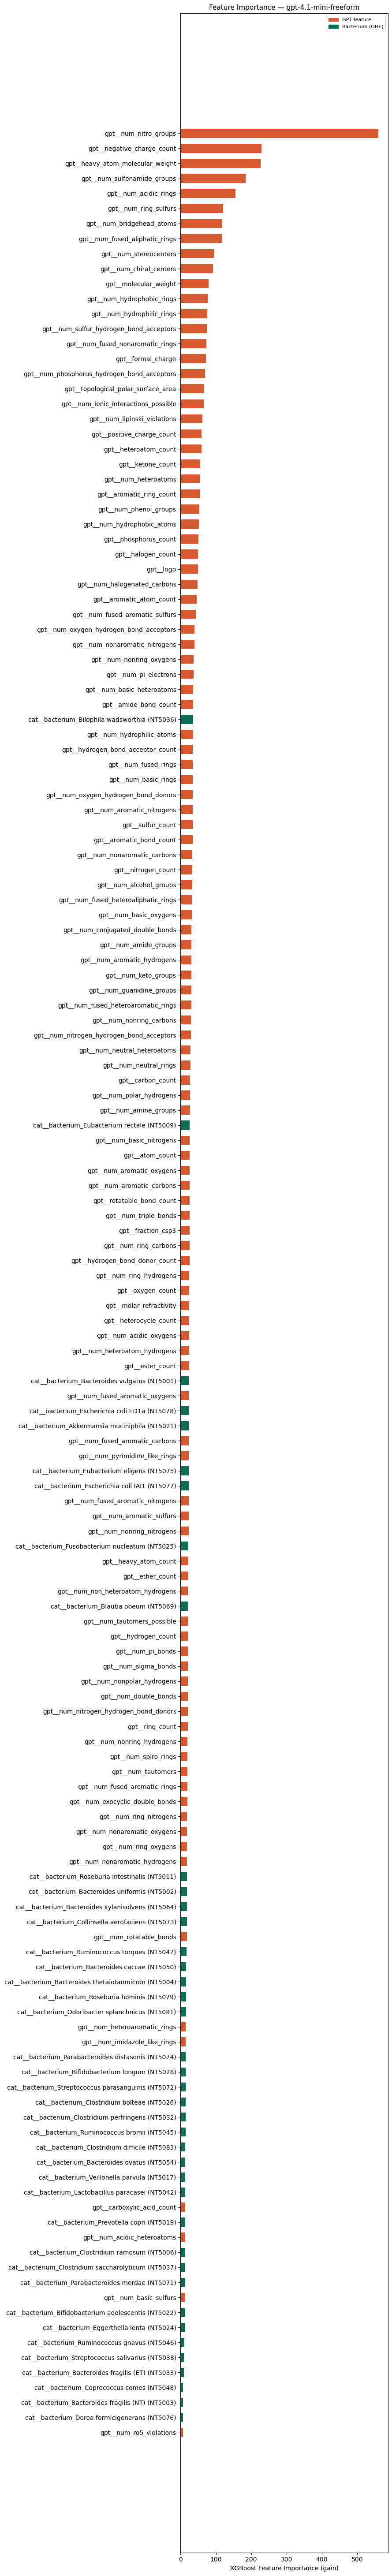

,f_idx,importance,feature_name
83,f83,559.426208,gpt__num_nitro_groups
68,f68,228.629898,gpt__negative_charge_count
71,f71,227.112732,gpt__heavy_atom_molecular_weight
84,f84,184.565353,gpt__num_sulfonamide_groups
143,f143,155.503754,gpt__num_acidic_rings
107,f107,120.826225,gpt__num_ring_sulfurs
76,f76,117.647476,gpt__num_bridgehead_atoms
149,f149,116.865402,gpt__num_fused_aliphatic_rings
124,f124,94.881920,gpt__num_stereocenters
89,f89,92.246719,gpt__num_chiral_centers


In [20]:
importances = model["booster"].get_score(importance_type="gain")
feat_names  = model["feature_names"]

imp_df = (pd.DataFrame({"f_idx": list(importances.keys()),
                         "importance": list(importances.values())})
            .assign(feature_name=lambda x: x["f_idx"].map(
                lambda f: feat_names[int(f[1:])] if f.startswith("f") else f))
            .sort_values("importance", ascending=False)
            .reset_index(drop=True))

# Top 10 overall
top10 = imp_df.head(10).sort_values("importance", ascending=True)
colors = ["#0F6E56" if "bacterium" in n else "#D85A30" for n in top10["feature_name"]]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10["feature_name"], top10["importance"], color=colors, height=0.6)
for bar, val in zip(bars, top10["importance"]):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}", va="center", fontsize=8)
ax.set_xlabel("XGBoost Feature Importance (gain)")
ax.set_title(f"Top 10 Features — {MODEL_TAG}", fontsize=11)
ax.legend(handles=[mpatches.Patch(color="#D85A30", label="GPT feature"),
                   mpatches.Patch(color="#0F6E56", label="Bacterium (OHE)")], fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "top10_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTop 10 features:")
display(imp_df.head(10)[["feature_name", "importance"]])
print(f"\nAll {len(imp_df)} features with non-zero importance:")
imp_df[["feature_name", "importance"]]

## 6. Save Outputs

In [21]:
per_strain_df.to_csv(OUT_DIR / f"per_strain_metrics_{MODEL_TAG}.csv", index=False)
print("Saved per-strain metrics")

paper = preds.copy()
paper["pred_id"] = paper["prestwick_ID"].astype(str) + ":" + paper["bacterium"].astype(str)
paper = paper.rename(columns={"proba": "antimicrobial_predictive_probability",
                               "pred_f1": "growth_inhibition"})
paper[["pred_id", "antimicrobial_predictive_probability", "growth_inhibition"]].to_csv(
    OUT_DIR / f"paper_style_predictions_{MODEL_TAG}.csv", index=False)
print("Saved paper-style predictions")

imp_df.to_csv(OUT_DIR / f"feature_importance_{MODEL_TAG}.csv", index=False)
print("Saved feature importance")

pd.DataFrame([{**summary, "model": MODEL_TAG, "best_params": str(best_params)}]).to_csv(
    OUT_DIR / f"summary_metrics_{MODEL_TAG}.csv", index=False)
print(f"Saved summary metrics\nAll outputs in: {OUT_DIR}")

Saved per-strain metrics
Saved paper-style predictions
Saved feature importance
Saved summary metrics
All outputs in: D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-4.1-mini-freeform
